# Spin-polarised-current-driven domain wall

**Author**: Marijan Beg, Weiwei Wang

**Date**: 18 Mar 2016

This notebook can be downloaded from the github repository, found [here](https://github.com/computationalmodelling/fidimag/blob/master/doc/ipynb/current-driven-domain-wall.ipynb).

### Problem specification

The simulated sample is a 1D nanowire cuboid with $L=1000 \,\text{nm}$ length with finite difference discretisation $d_{x} = d_{y} = d_{z} = 2 \,\text{nm}$.

The material parameters (similar to permalloy) are:
    
- exchange energy constant $A = 1.3 \times 10^{-11} \,\text{J/m}$,
- magnetisation saturation $M_\text{s} = 8.6 \times 10^{5} \,\text{A/m}$,
- uniaxial anisotropy constant $K=5 \times 10^{4} \,\text{J/m}^{3}$ with $(0, 0, 1)$ easy-axis,
- Gilbert damping $\alpha = 0.5$.

After the system is relaxed to a domain wall, a spin-polarised current with $J=1 \times 10^{12} \text{A/m}^{2}$ density is applied in the positive x direction $(1, 0, 0)$.

### Simulation functions

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from fidimag.micro import Sim, UniformExchange, UniaxialAnisotropy
from fidimag.common import CuboidMesh
%matplotlib inline

We start by defining parameters and a function for initialising the system so that it relaxes to the domain wall.

In [2]:
Ms = 8.6e5  # magnetisation saturation (A/m)
A = 1.3e-11  # exchange energy constant (J/m)
alpha = 0.5  # Gilbert damping
gamma = 2.211e5  # gyromagnetic ration (m/As)
K = 5e4  # uniaxial anisotropy constant (J/m**3)
J = 1e12  # spin-polarised current density (A/m**2)
beta = 1  # STT parameter

def init_m(pos):
    x = pos[0]

    if x < 200:
        return (1, 0, 0)
    elif 200 <= x < 300:
        return (0, 1, 1)
    else:
        return (-1, 0, 0)

Using this function, we create a new function which relaxes the system to its equilibrium (domain wall) state according to the problem specification.

In [3]:
def relax_system(mesh):
    # Create a simulation object.
    sim = Sim(mesh)

    # Set simulation parameters.
    sim.driver.set_tols(rtol=1e-8, atol=1e-8)
    sim.driver.alpha = alpha
    sim.driver.gamma = gamma
    sim.Ms = Ms

    # Add energies to the system.
    sim.add(UniformExchange(A=A))
    sim.add(UniaxialAnisotropy(K))

    # Initialise the system.
    sim.set_m(init_m)
    
    # Relax the system and save the state in m0.npy
    sim.driver.relax(dt=1e-14, stopping_dmdt=0.01, max_steps=5000,
                     save_m_steps=None, save_vtk_steps=None)

    np.save('m0.npy', sim.spin)

A plot of the system's magnetisation can be created using the following convenience function.

In [4]:
def plot_magnetisation(components):
    plt.figure(figsize=(8, 6))

    comp = {'mx': 0, 'my': 1, 'mz': 2}

    for element in components:
        data = np.load(element[0])
        data.shape = (-1, 3)

        mc = data[:, comp[element[1]]]
        
        # The label is the component and the file name
        plt.plot(mc, label=element[1])

    plt.legend()
    plt.xlabel('x (nm)')
    plt.ylabel('mx, my')
    plt.grid()
    plt.ylim([-1.05, 1.05])

Finally, we create a function for driving a domain wall using the spin-polarised current. All *npy* and *vtk* files are saved in the **\{simulation_name\}_npys** and **\{simulation_name\}_vtks** folders, respectively.

In [5]:
def excite_system(mesh, time, snapshots):
    # Specify the stt dynamics in the simulation
    sim = Sim(mesh, name='dyn', driver='llg_stt')
    
    # Set the simulation parameters
    sim.driver.set_tols(rtol=1e-12, atol=1e-14)
    sim.driver.alpha = alpha
    sim.driver.gamma = gamma
    sim.Ms = Ms

    # Add energies to the system.
    sim.add(UniformExchange(A=A))
    sim.add(UniaxialAnisotropy(K))

    # Load the initial state from the npy file saved in the realxation stage.
    sim.set_m(np.load('m0.npy'))

    # Set the spin-polarised current in the x direction.
    sim.driver.jx = J
    sim.driver.beta = beta

    # The simulation will run for x ns and save
    # 'snaps' snapshots of the system in the process
    ts = np.linspace(0, time, snapshots)

    for t in ts:
        sim.driver.run_until(t)
        sim.save_vtk()
        sim.save_m()


### Simulation

Before we run a simulation using previously defined functions, a finite difference mesh must be created.

In [6]:
L = 2000  # nm
dx = dy = dz = 2  # nm

mesh = CuboidMesh(nx=int(L/dx), ny=1, nz=1, dx=dx, dy=dy, dz=dz, unit_length=1e-9)

Now, the system is relaxed and the domain wall equilibrium state is obtained, saved, and later used in the next stage.

In [7]:
#NBVAL_IGNORE_OUTPUT
relax_system(mesh)

#1    t=1e-14    dt=1e-14 max_dmdt=6.8e+04
#2    t=2e-14    dt=1e-14 max_dmdt=6.76e+04
#3    t=3.05e-14 dt=1.05e-14 max_dmdt=6.72e+04
#4    t=4.09e-14 dt=1.05e-14 max_dmdt=6.68e+04
#5    t=5.14e-14 dt=1.05e-14 max_dmdt=6.65e+04
#6    t=6.19e-14 dt=1.05e-14 max_dmdt=6.61e+04
#7    t=7.23e-14 dt=1.05e-14 max_dmdt=6.57e+04
#8    t=8.28e-14 dt=1.05e-14 max_dmdt=6.52e+04
#9    t=9.33e-14 dt=1.05e-14 max_dmdt=6.48e+04
#10   t=1.04e-13 dt=1.05e-14 max_dmdt=6.44e+04
#11   t=1.23e-13 dt=1.91e-14 max_dmdt=6.38e+04
#12   t=1.42e-13 dt=1.91e-14 max_dmdt=6.3e+04
#13   t=1.61e-13 dt=1.91e-14 max_dmdt=6.22e+04
#14   t=1.8e-13  dt=1.91e-14 max_dmdt=6.13e+04
#15   t=1.99e-13 dt=1.91e-14 max_dmdt=6.05e+04
#16   t=2.18e-13 dt=1.91e-14 max_dmdt=5.96e+04
#17   t=2.37e-13 dt=1.91e-14 max_dmdt=5.87e+04
#18   t=2.56e-13 dt=1.91e-14 max_dmdt=5.77e+04
#19   t=2.75e-13 dt=1.91e-14 max_dmdt=5.68e+04
#20   t=3.09e-13 dt=3.37e-14 max_dmdt=5.54e+04
#21   t=3.43e-13 dt=3.37e-14 max_dmdt=5.36e+04
#22   t=3.77e-13 dt=3

#205  t=1.79e-11 dt=3.05e-13 max_dmdt=1.08e+03
#206  t=1.82e-11 dt=3.05e-13 max_dmdt=1.07e+03
#207  t=1.85e-11 dt=3.05e-13 max_dmdt=1.05e+03
#208  t=1.88e-11 dt=3.05e-13 max_dmdt=1.03e+03
#209  t=1.91e-11 dt=3.05e-13 max_dmdt=1.02e+03
#210  t=1.94e-11 dt=3.05e-13 max_dmdt=1.01e+03
#211  t=1.97e-11 dt=3.05e-13 max_dmdt=993
#212  t=2e-11    dt=3.05e-13 max_dmdt=980
#213  t=2.03e-11 dt=3.05e-13 max_dmdt=968
#214  t=2.06e-11 dt=3.05e-13 max_dmdt=956
#215  t=2.09e-11 dt=3.05e-13 max_dmdt=944
#216  t=2.12e-11 dt=3.05e-13 max_dmdt=933
#217  t=2.15e-11 dt=3.05e-13 max_dmdt=921
#218  t=2.18e-11 dt=3.05e-13 max_dmdt=910
#219  t=2.22e-11 dt=3.05e-13 max_dmdt=899
#220  t=2.25e-11 dt=3.05e-13 max_dmdt=888
#221  t=2.28e-11 dt=3.05e-13 max_dmdt=878
#222  t=2.31e-11 dt=3.05e-13 max_dmdt=868
#223  t=2.34e-11 dt=3.05e-13 max_dmdt=858
#224  t=2.37e-11 dt=3.05e-13 max_dmdt=848
#225  t=2.4e-11  dt=3.05e-13 max_dmdt=839
#226  t=2.43e-11 dt=3.05e-13 max_dmdt=830
#227  t=2.46e-11 dt=3.05e-13 max_dmdt=821
#228

#435  t=1.1e-10  dt=1.21e-12 max_dmdt=605
#436  t=1.11e-10 dt=1.21e-12 max_dmdt=603
#437  t=1.13e-10 dt=1.21e-12 max_dmdt=601
#438  t=1.14e-10 dt=1.21e-12 max_dmdt=598
#439  t=1.15e-10 dt=1.21e-12 max_dmdt=596
#440  t=1.16e-10 dt=1.21e-12 max_dmdt=593
#441  t=1.17e-10 dt=1.21e-12 max_dmdt=590
#442  t=1.19e-10 dt=1.21e-12 max_dmdt=587
#443  t=1.2e-10  dt=1.21e-12 max_dmdt=584
#444  t=1.21e-10 dt=1.21e-12 max_dmdt=582
#445  t=1.22e-10 dt=1.21e-12 max_dmdt=579
#446  t=1.23e-10 dt=1.21e-12 max_dmdt=575
#447  t=1.25e-10 dt=1.21e-12 max_dmdt=572
#448  t=1.26e-10 dt=1.21e-12 max_dmdt=569
#449  t=1.27e-10 dt=1.21e-12 max_dmdt=566
#450  t=1.28e-10 dt=1.21e-12 max_dmdt=562
#451  t=1.29e-10 dt=1.21e-12 max_dmdt=559
#452  t=1.31e-10 dt=1.21e-12 max_dmdt=556
#453  t=1.32e-10 dt=1.21e-12 max_dmdt=552
#454  t=1.33e-10 dt=1.21e-12 max_dmdt=548
#455  t=1.34e-10 dt=1.21e-12 max_dmdt=545
#456  t=1.35e-10 dt=1.21e-12 max_dmdt=541
#457  t=1.37e-10 dt=1.21e-12 max_dmdt=537
#458  t=1.38e-10 dt=1.21e-12 max_d

#604  t=4.45e-10 dt=2.74e-12 max_dmdt=24.4
#605  t=4.48e-10 dt=2.74e-12 max_dmdt=23.8
#606  t=4.5e-10  dt=2.74e-12 max_dmdt=23.2
#607  t=4.53e-10 dt=2.74e-12 max_dmdt=22.6
#608  t=4.57e-10 dt=4.11e-12 max_dmdt=21.9
#609  t=4.61e-10 dt=4.11e-12 max_dmdt=21.1
#610  t=4.65e-10 dt=4.11e-12 max_dmdt=20.3
#611  t=4.69e-10 dt=4.11e-12 max_dmdt=19.6
#612  t=4.74e-10 dt=4.11e-12 max_dmdt=18.9
#613  t=4.78e-10 dt=4.11e-12 max_dmdt=18.2
#614  t=4.82e-10 dt=4.11e-12 max_dmdt=17.5
#615  t=4.86e-10 dt=4.11e-12 max_dmdt=16.8
#616  t=4.9e-10  dt=4.11e-12 max_dmdt=16.2
#617  t=4.94e-10 dt=4.11e-12 max_dmdt=15.6
#618  t=4.98e-10 dt=4.11e-12 max_dmdt=15
#619  t=5.02e-10 dt=4.11e-12 max_dmdt=14.5
#620  t=5.06e-10 dt=4.11e-12 max_dmdt=14
#621  t=5.11e-10 dt=4.11e-12 max_dmdt=13.4
#622  t=5.15e-10 dt=4.11e-12 max_dmdt=12.9
#623  t=5.19e-10 dt=4.11e-12 max_dmdt=12.5
#624  t=5.23e-10 dt=4.11e-12 max_dmdt=12
#625  t=5.27e-10 dt=4.11e-12 max_dmdt=11.6
#626  t=5.31e-10 dt=4.11e-12 max_dmdt=11.1
#627  t=5.35e-10 

#686  t=8.25e-10 dt=6.18e-12 max_dmdt=0.804
#687  t=8.32e-10 dt=6.18e-12 max_dmdt=0.762
#688  t=8.38e-10 dt=6.18e-12 max_dmdt=0.722
#689  t=8.44e-10 dt=6.18e-12 max_dmdt=0.684
#690  t=8.5e-10  dt=6.18e-12 max_dmdt=0.648
#691  t=8.56e-10 dt=6.18e-12 max_dmdt=0.613
#692  t=8.63e-10 dt=6.18e-12 max_dmdt=0.581
#693  t=8.69e-10 dt=6.18e-12 max_dmdt=0.551
#694  t=8.75e-10 dt=6.18e-12 max_dmdt=0.522
#695  t=8.81e-10 dt=6.18e-12 max_dmdt=0.494
#696  t=8.87e-10 dt=6.18e-12 max_dmdt=0.468
#697  t=8.93e-10 dt=6.18e-12 max_dmdt=0.443
#698  t=9e-10    dt=6.18e-12 max_dmdt=0.42
#699  t=9.06e-10 dt=6.18e-12 max_dmdt=0.398
#700  t=9.12e-10 dt=6.18e-12 max_dmdt=0.377
#701  t=9.18e-10 dt=6.18e-12 max_dmdt=0.357
#702  t=9.28e-10 dt=9.45e-12 max_dmdt=0.334
#703  t=9.37e-10 dt=9.45e-12 max_dmdt=0.307
#704  t=9.47e-10 dt=9.45e-12 max_dmdt=0.283
#705  t=9.56e-10 dt=9.45e-12 max_dmdt=0.261
#706  t=9.65e-10 dt=9.45e-12 max_dmdt=0.24
#707  t=9.75e-10 dt=9.45e-12 max_dmdt=0.221
#708  t=9.84e-10 dt=9.45e-12 max_d

#730  t=1.21e-09 dt=1.42e-11 max_dmdt=0.0306
#731  t=1.22e-09 dt=1.42e-11 max_dmdt=0.0271
#732  t=1.23e-09 dt=1.42e-11 max_dmdt=0.0241
#733  t=1.25e-09 dt=1.42e-11 max_dmdt=0.0213
#734  t=1.26e-09 dt=1.42e-11 max_dmdt=0.0189
#735  t=1.28e-09 dt=1.42e-11 max_dmdt=0.0168
#736  t=1.29e-09 dt=1.42e-11 max_dmdt=0.0149
#737  t=1.31e-09 dt=1.42e-11 max_dmdt=0.0132
#738  t=1.32e-09 dt=1.42e-11 max_dmdt=0.0117
#739  t=1.33e-09 dt=1.42e-11 max_dmdt=0.0104
#740  t=1.35e-09 dt=1.42e-11 max_dmdt=0.00922


Plot the magnetisation components of the relaxed state.

/var/folders/v2/rvntygp10z52qbtk4zpv2h180000gn/T/ipykernel_27248/327596027.py:8: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  data.shape = (-1, 3)


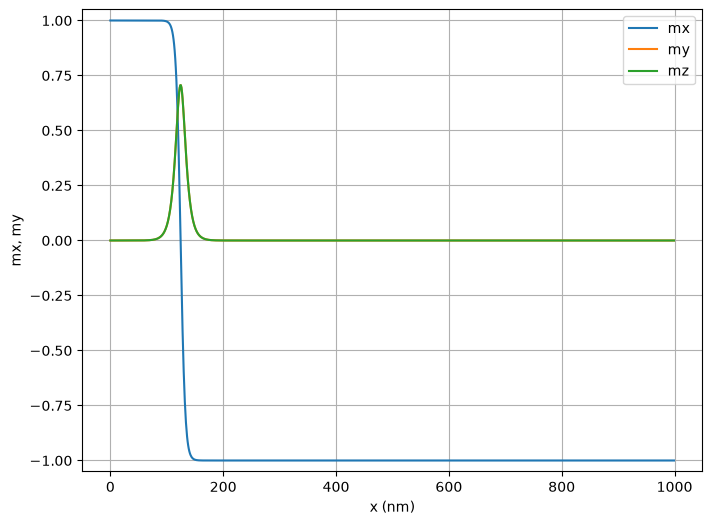

In [8]:
#NBVAL_IGNORE_OUTPUT
plot_magnetisation([['m0.npy', 'mx'], ['m0.npy', 'my'], ['m0.npy', 'mz']])

The DW is at the maximum value of $|m_z|$ or $|m_y|$. Consequently, the domain wall position is:

In [9]:
m0_z = np.load('m0.npy').reshape(-1, 3)[:, 2]
x = np.arange(len(m0_z))
index_max = np.argmax(np.abs(m0_z))

print('Maximum |m_z| at x = %s' % x[index_max])

Maximum |m_z| at x = 124


Using the obtained domain wall equilibrium state, we now simulate its motion in presence of a spin-polarised current.

In [10]:
#NBVAL_IGNORE_OUTPUT
excite_system(mesh, 1.5e-9, 151)

We plot once again to compare the initial state with the ones after a SP current was applied.

/var/folders/v2/rvntygp10z52qbtk4zpv2h180000gn/T/ipykernel_27248/327596027.py:8: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  data.shape = (-1, 3)


(0.0, 200.0)

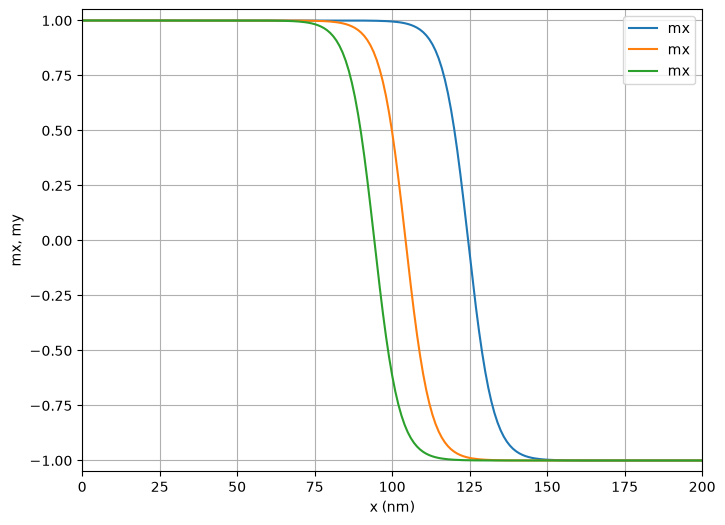

In [11]:
#NBVAL_IGNORE_OUTPUT
# We can plot the m_x component for a number snapshots
# to observe the DW motion
# We will plot the 100th and 150th files (we can also compute
# until the system reaches ~5 ns to improve the effect)
plot_magnetisation([['m0.npy', 'mx'],
                    ['dyn_npys/m_100.npy', 'mx'],
                    ['dyn_npys/m_150.npy', 'mx']])
plt.xlim([0, 200])